    ## Análisis y Predicción de la Matriz de Generación de Energías Alterativas en Argentina (2011–2020)


<h2>Contexto</h2>
El sistema eléctrico actual requiere anticipar la energía suministrada por las fuentes alternativas para cubrir la demanda y gestionar la variación energética.

## Objetivo del proyecto
**Predecir la cantidad de energia renovable mensual que generan las privincias según el tipo de fuente y el mes del año para anticipar la oferta electrica y crear un plan estrategico.
En este análisis también podremos observar que provincias tienen buen nivel o potencial de desarrollo
**

Energía pah: pequeños aprovechamientos hidroeléctricos, forma de energía renovable utiliza la fuerza del agua para generar electricidad

**Análisis Exploratorio de Datos**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from matplotlib.pyplot import axes

In [6]:
pd.read_csv("../kaggle/energias-alternativas.csv", encoding='latin-1')

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200


In [7]:
df = pd.read_csv("../kaggle/energias-alternativas.csv", encoding='latin-1')

In [8]:
df

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200


**Exploración**

In [9]:
df.head(n=5)

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924


Las columnas son:

- sector_id:	Código numérico del sector
- sector_nombre:	Nombre del sector
- variable_id: Código único de cada combinación energía + indicador
- actividad_producto_nombre: Tipo de energía
- indicador: Qué se está midiendo
- unidad_de_medida: Unidad de valor
- fuente: Organismo que publica el dato
- frecuencia_nombre: Periodicidad de los datos
- cobertura_nombre: Cobertura geográfica general
- alcance_tipo: Nivel geográfico del dato
- alcance_id: Código de la provincia
- alcance_nombre: Nombre de la procincia
- indice_tiempo: Fecha del registro
- valor: La medición

**Tipos de Datos de las Columnas**

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5311 entries, 0 to 5310
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sector_id                  5311 non-null   int64  
 1   sector_nombre              5311 non-null   str    
 2   variable_id                5311 non-null   int64  
 3   actividad_producto_nombre  5311 non-null   str    
 4   indicador                  5311 non-null   str    
 5   unidad_de_medida           5311 non-null   str    
 6   fuente                     5311 non-null   str    
 7   frecuencia_nombre          5311 non-null   str    
 8   cobertura_nombre           5311 non-null   str    
 9   alcance_tipo               5311 non-null   str    
 10  alcance_id                 5311 non-null   int64  
 11  alcance_nombre             5311 non-null   str    
 12  indice_tiempo              5311 non-null   str    
 13  valor                      5311 non-null   float64
dtypes: 

In [54]:
print(f'El dataset tiene en total {df.shape[0]} filas y {df.shape[1]} columnas')

El dataset tiene en total 5311 filas y 16 columnas


**Valores Nulos**

In [55]:
df.isna().sum()

sector_id                    0
sector_nombre                0
variable_id                  0
actividad_producto_nombre    0
indicador                    0
unidad_de_medida             0
fuente                       0
frecuencia_nombre            0
cobertura_nombre             0
alcance_tipo                 0
alcance_id                   0
alcance_nombre               0
indice_tiempo                0
valor                        0
año                          0
mes                          0
dtype: int64

*Ninguna variable parece tener valores nulos*

In [56]:
(df == 0). sum()
# Cantidad de ceros por columna

sector_id                      0
sector_nombre                  0
variable_id                    0
actividad_producto_nombre      0
indicador                      0
unidad_de_medida               0
fuente                         0
frecuencia_nombre              0
cobertura_nombre               0
alcance_tipo                   0
alcance_id                     0
alcance_nombre                 0
indice_tiempo                  0
valor                        497
año                            0
mes                            0
dtype: int64

In [57]:
df.dtypes

sector_id                             int64
sector_nombre                           str
variable_id                           int64
actividad_producto_nombre               str
indicador                               str
unidad_de_medida                        str
fuente                                  str
frecuencia_nombre                       str
cobertura_nombre                        str
alcance_tipo                            str
alcance_id                            int64
alcance_nombre                          str
indice_tiempo                datetime64[us]
valor                               float64
año                                   int32
mes                                   int32
dtype: object

**Variables Numéricas y Categóricas**
Numéricas (cuantitativas):
- valor

Identificadoras:
- sector_id
- variable_id
- alcance_id

Categóricas:
- sector_nombre
- actividad_producto_nombre
- indicador
- unidad_de_medida
- fuente
- frecuencia_nombre
- cobertura_nombre
- alcance_tipo
- alcance_nombre
- indice_tiempo

## Transformación de los datos

In [58]:
df.duplicated().sum()#comprovamos los duplicados
df['indice_tiempo']=pd.to_datetime(df['indice_tiempo'])
df['año']=df['indice_tiempo'].dt.year #agregamos columnas interesantes para series temporales
df['mes']=df['indice_tiempo'].dt.month
df

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor,año,mes
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000,2012,1
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000,2012,2
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000,2012,3
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000,2012,4
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924,2012,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200,2020,8
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200,2020,9
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200,2020,10
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200,2020,11


## Análisis varibales categóricas

Exploramos las variables categóricas
¿Cuántos valores únicos hay en cada columna de las categóricas? Es decir, ¿cuántas categorías hay?

In [59]:
cols_cat=df.select_dtypes(include=["object","string"]).columns # agregamos está linea para usar la var
df[cols_cat].nunique()
# Cantidad de categorías distintas por columna
#Indentificamos columnas redundantes

sector_nombre                 1
actividad_producto_nombre     6
indicador                     2
unidad_de_medida              2
fuente                        1
frecuencia_nombre             1
cobertura_nombre              1
alcance_tipo                  1
alcance_nombre               19
dtype: int64

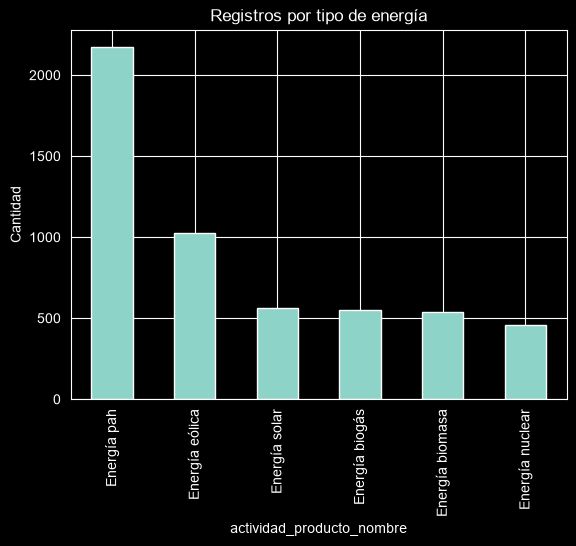

In [60]:
df['actividad_producto_nombre'].value_counts().plot(kind='bar')
plt.title('Registros por tipo de energía')
plt.ylabel('Cantidad')
plt.show()

In [64]:
excluyendo=['indice_tiempo', 'año', 'mes']
df.drop(columns=excluyendo).describe().round(2)

,sector_id,variable_id,alcance_id,valor
count,5311.0,5311.00,5311.00,5311.00
mean,25.0,445.45,46.70,20086.47
std,0.0,2.84,29.19,75980.81
min,25.0,440.00,6.00,0.00
25%,25.0,443.00,14.00,19.50
50%,25.0,447.00,50.00,349.85
75%,25.0,448.00,70.00,9156.32
max,25.0,450.00,90.00,752501.26


In [65]:
df

,sector_id,sector_nombre,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,fuente,frecuencia_nombre,cobertura_nombre,alcance_tipo,alcance_id,alcance_nombre,indice_tiempo,valor,año,mes
0,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-01-01,0.000,2012,1
1,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-02-01,0.000,2012,2
2,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-03-01,0.000,2012,3
3,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-04-01,0.000,2012,4
4,25,Energías alternativas,440,Energía biogás,Generación,MWh,CAMMESA,Mensual,Nacional,PROVINCIA,6,BUENOS AIRES,2012-05-01,764.924,2012,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5306,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-08-01,61.200,2020,8
5307,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-09-01,61.200,2020,9
5308,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-10-01,61.200,2020,10
5309,25,Energías alternativas,450,Energía solar,Potencia instalada,MW,CAMMESA,Mensual,Nacional,PROVINCIA,74,SAN LUIS,2020-11-01,61.200,2020,11


## Analisis bivariado y multivalorado

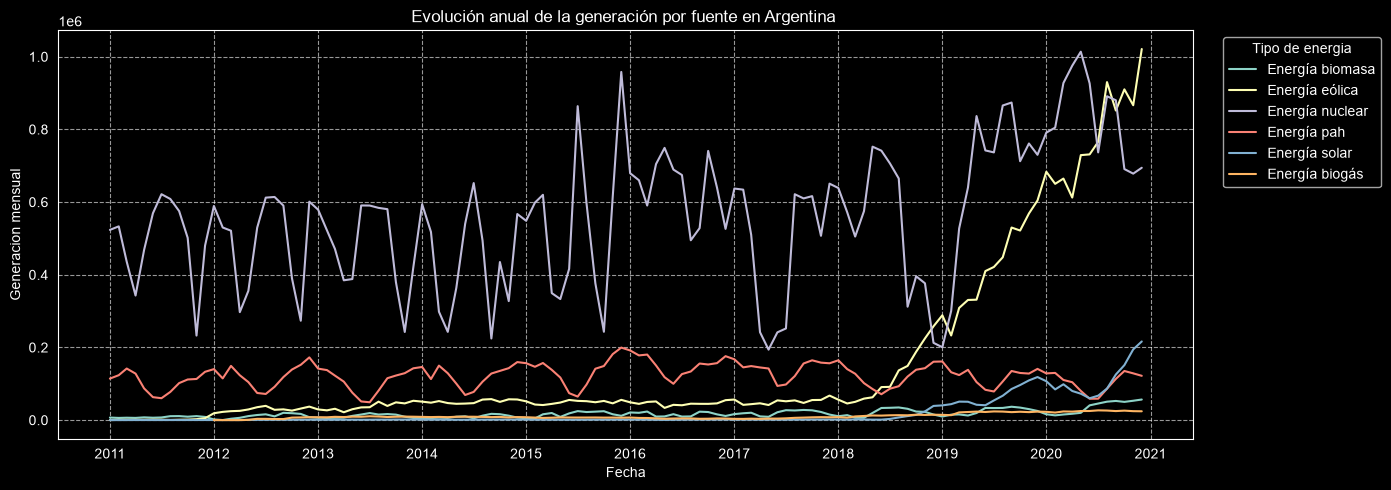

In [100]:
#evolución temporal del 'valor' por tipo de energia
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
df_generacion=df[df['indicador']=='Generación'] #evitamos mezclar unidades de mwh
df_agrupado=df_generacion.groupby(['indice_tiempo', 'actividad_producto_nombre'])['valor'].sum().reset_index() #agrupamos sumando la generacion de energia de todas las provincias
plt.figure(figsize = (14, 5)) #creamos el lienzo
sns.lineplot(
    data=df_agrupado,
    x='indice_tiempo',
    y='valor',
    hue='actividad_producto_nombre',
)
plt.title("Evolución anual de la generación por fuente en Argentina ")
plt.xlabel('Fecha')
plt.ylabel('Generacion mensual')
plt.legend(title='Tipo de energia', bbox_to_anchor=(1.02 ,1), loc='upper left')#cuadro de informacion
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [113]:
columnas_constantes=[
    'sector_nombre',
    'fuente',
    'frecuencia_nombre',
    'cobertura_nombre',
    'alcance_tipo'
]
df=df.drop(columns=columnas_constantes)
df.head(10)

,sector_id,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,alcance_id,alcance_nombre,indice_tiempo,valor,año,mes
0,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-01-01,0.000,2012,1
1,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-02-01,0.000,2012,2
2,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-03-01,0.000,2012,3
3,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-04-01,0.000,2012,4
4,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-05-01,764.924,2012,5
5,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-06-01,3478.232,2012,6
6,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-07-01,3395.954,2012,7
7,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-08-01,2928.667,2012,8
8,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-09-01,2841.751,2012,9
9,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-10-01,6902.033,2012,10


In [102]:
df['indicador']

0               Generación
1               Generación
2               Generación
3               Generación
4               Generación
               ...        
5306    Potencia instalada
5307    Potencia instalada
5308    Potencia instalada
5309    Potencia instalada
5310    Potencia instalada
Name: indicador, Length: 5311, dtype: str

Se eliminaron las columnas sector_nombre, fuente, frecuencia_nombre, cobertura_nombre y alcance_tipo porque no aportan valor estadístico al proyecto

Tener en cuenta que hay valores 0 de distintas fuentes e indicadores, representan meses sin generación, ausencia de potencia instalada o periodos anteriores a la entrada en funcionamiento de una instalación.
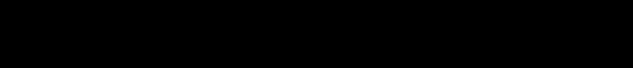
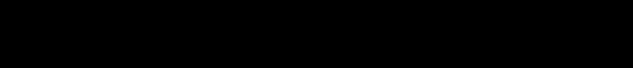

In [103]:
resumen_ceros=(
    df.assign(es_cero=df['valor'].eq(0)).groupby(
        ["indicador","actividad_producto_nombre"],
        as_index=False)
        .agg(
           registros=("valor","size"),
           cantidad_ceros=("es_cero", "sum")
        )
)
resumen_ceros["porcentaje_ceros"]=(
    resumen_ceros["cantidad_ceros"]/resumen_ceros["registros"]*100).round(2)
resumen_ceros

,indicador,actividad_producto_nombre,registros,cantidad_ceros,porcentaje_ceros
0,Generación,Energía biogás,276,38,13.77
1,Generación,Energía biomasa,540,126,23.33
2,Generación,Energía eólica,528,54,10.23
3,Generación,Energía nuclear,240,53,22.08
4,Generación,Energía pah,1200,77,6.42
5,Generación,Energía solar,288,44,15.28
6,Potencia instalada,Energía biogás,276,35,12.68
7,Potencia instalada,Energía eólica,499,21,4.21
8,Potencia instalada,Energía nuclear,216,0,0.00
9,Potencia instalada,Energía pah,972,0,0.00


entendemos que los 0 anteriores a

## Cobertura del tiempo por energía

In [114]:
cobertura_temporal=(
    df_generacion.groupby("actividad_producto_nombre").agg(
        fecha_inicio=("indice_tiempo", "min"),
        fecha_fin=("indice_tiempo", "max"),
        provincias=("alcance_nombre","nunique"),
        registros=("valor","size")
    ).reset_index())
cobertura_temporal

,actividad_producto_nombre,fecha_inicio,fecha_fin,provincias,registros
0,Energía biogás,2012-01-01,2020-12-01,5,276
1,Energía biomasa,2011-01-01,2020-12-01,7,540
2,Energía eólica,2011-01-01,2020-12-01,9,528
3,Energía nuclear,2011-01-01,2020-12-01,2,240
4,Energía pah,2011-01-01,2020-12-01,10,1200
5,Energía solar,2011-01-01,2020-12-01,7,288


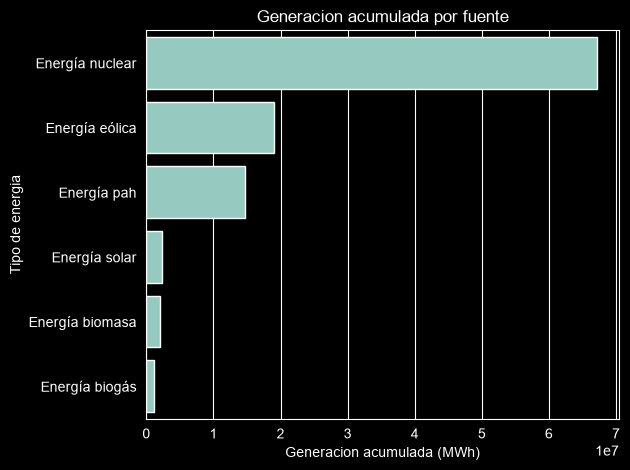

In [115]:
generacion_fuente=(
    df_generacion.groupby("actividad_producto_nombre", as_index=False)["valor"].sum().sort_values("valor", ascending=False)
)
sns.barplot(
    data=generacion_fuente,
    x="valor",
    y="actividad_producto_nombre"
)
plt.title("Generacion acumulada por fuente")
plt.xlabel("Generacion acumulada (MWh)")
plt.ylabel("Tipo de energia")
plt.tight_layout()
plt.show()


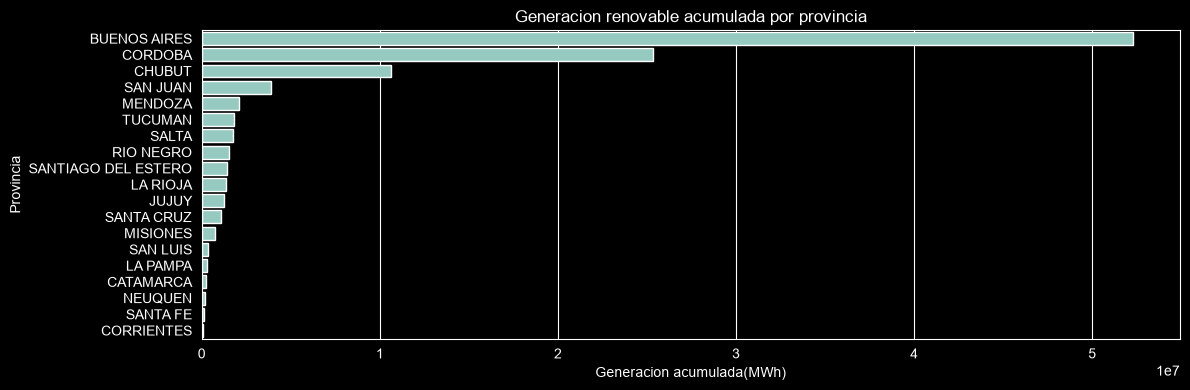

In [106]:
generacion_provincia=(
    df_generacion.groupby("alcance_nombre", as_index=False)["valor"].sum().sort_values("valor", ascending=False)
)
plt.figure(figsize = (12, 4))
sns.barplot(
    data=generacion_provincia,
    x="valor",
    y="alcance_nombre"
)
plt.title("Generacion renovable acumulada por provincia")
plt.xlabel ("Generacion acumulada(MWh)")
plt.ylabel("Provincia")
plt.tight_layout()
plt.show()


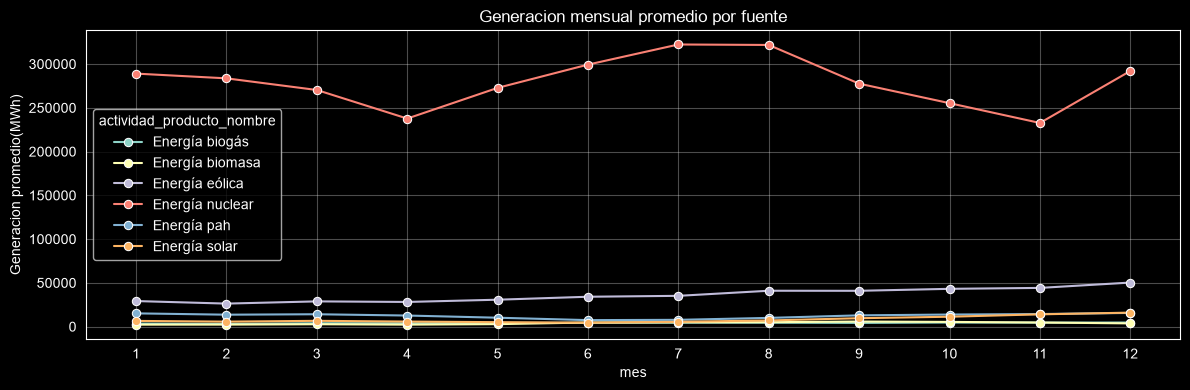

In [107]:
generacion_mes=(
    df_generacion.groupby(
        ["mes", "actividad_producto_nombre"], as_index=False)["valor"].mean()
    )
plt.figure(figsize = (12, 4))
sns.lineplot(
    data=generacion_mes,
    x="mes",
    y="valor",
    hue="actividad_producto_nombre",
    marker="o"
)
plt.xticks(range(1,13))
plt.title("Generacion mensual promedio por fuente")
plt.xlabel("mes")
plt.ylabel("Generacion promedio(MWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [125]:
df_generacion_1 = df[df["indicador"]=="Generación"]
df_potencia_1 = df[df["indicador"]=="Potencia instalada"]
potencia_anual= df_potencia_1.groupby("año", as_index=False)["valor"].sum()
potencia_fuente=df_potencia_1.groupby("actividad_producto_nombre", as_index=False)["valor"].sum().sort_values("valor", ascending=False)

C:\Users\F-PC-100\AppData\Local\Temp\ipykernel_15464\4256549993.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=potencia_fuente, x="actividad_producto_nombre", y="valor", palette="Set2", ax=axes[1]


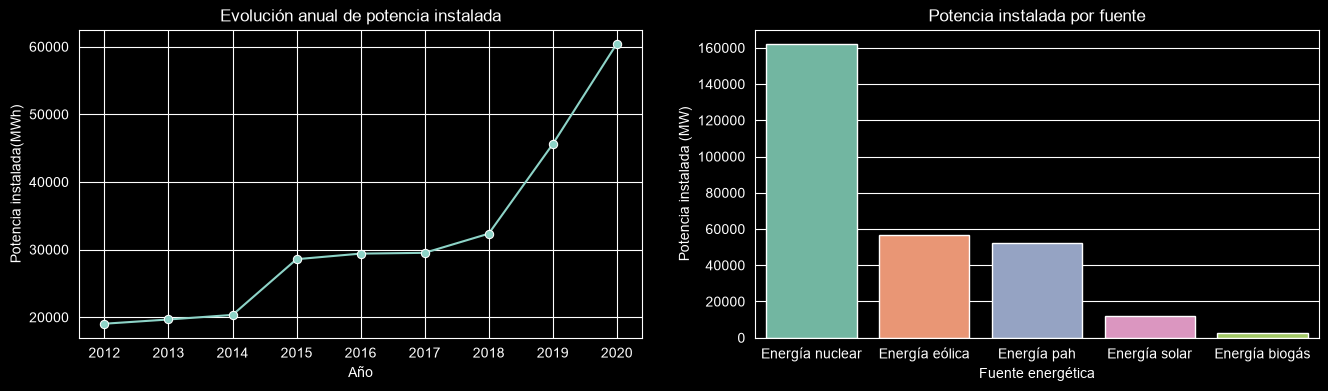

In [129]:
fig, axes=plt.subplots(1, 2 ,figsize=(16 , 4))
sns.lineplot(data=potencia_anual, x="año", y="valor", marker="o", ax=axes[0]
            )
axes[0].set_title("Evolución anual de potencia instalada")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Potencia instalada(MWh)")
sns.barplot(data=potencia_fuente, x="actividad_producto_nombre", y="valor", palette="Set2", ax=axes[1]
            )
axes[1].set_title("Potencia instalada por fuente")
axes[1].set_xlabel("Fuente energética")
axes[1].set_ylabel("Potencia instalada (MW)")
plt.show()

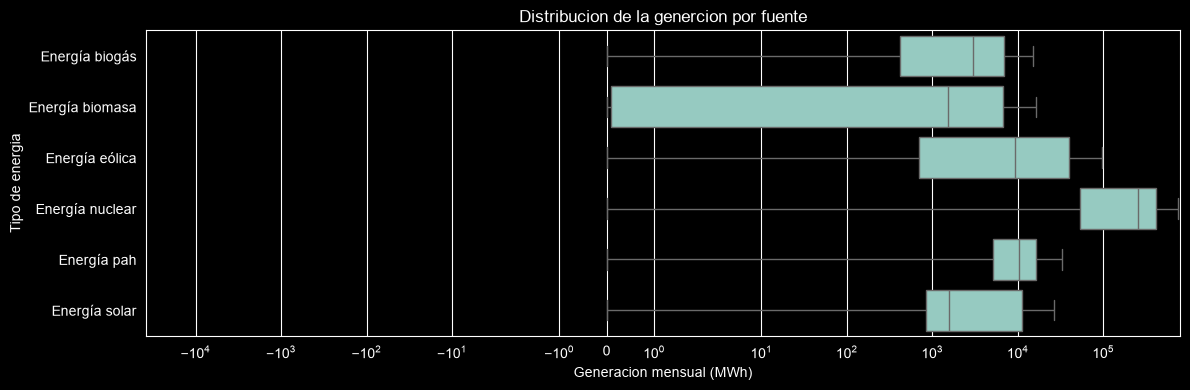

In [132]:
plt.figure(figsize=(12 , 4))
sns.boxplot(
    data=df_generacion,
    x="valor",
    y="actividad_producto_nombre",
    showfliers=False
)
plt.xscale("symlog")
plt.title("Distribucion de la genercion por fuente")
plt.xlabel("Generacion mensual (MWh)")
plt.ylabel("Tipo de energia")
plt.tight_layout()
plt.show()

## Observaciones
No hay valores nulos y tampoco registros duplicados
Hay gran diferencia en los valores de las fuentes energéticas
La energía nuclear concentra gran parte de la generación
Algunas fuentes se comportan estacionalmente
Buenos aires concentra gran parte de la producción


In [116]:
df #contiene los datos para el modelo

,sector_id,variable_id,actividad_producto_nombre,indicador,unidad_de_medida,alcance_id,alcance_nombre,indice_tiempo,valor,año,mes
0,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-01-01,0.000,2012,1
1,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-02-01,0.000,2012,2
2,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-03-01,0.000,2012,3
3,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-04-01,0.000,2012,4
4,25,440,Energía biogás,Generación,MWh,6,BUENOS AIRES,2012-05-01,764.924,2012,5
...,...,...,...,...,...,...,...,...,...,...,...
5306,25,450,Energía solar,Potencia instalada,MW,74,SAN LUIS,2020-08-01,61.200,2020,8
5307,25,450,Energía solar,Potencia instalada,MW,74,SAN LUIS,2020-09-01,61.200,2020,9
5308,25,450,Energía solar,Potencia instalada,MW,74,SAN LUIS,2020-10-01,61.200,2020,10
5309,25,450,Energía solar,Potencia instalada,MW,74,SAN LUIS,2020-11-01,61.200,2020,11



Procedemos a construir modelos de aprendizaje supervisado para predecir la generación mensual de energía:
    Provincia
    Tipo de energía
    Año
    Mes
## Clasificación  ->Predecir la cantidad mensual de generación eléctrica.